<a href="https://colab.research.google.com/github/Kuper994/Software-Project/blob/main/scikit_learn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning

Last weeks we focused on: preprocessing, visualization & analysis

Today: ML

We are given a dataset and would like to perform a task with it.

## Basic Example - House Price Prediction
Given: a dataset of N samples
$(x_1,y_1),...(x_n,y_n)$

$x - square$

$y - price$

Task: what is the price of house that has $x$ square ?

### One dimensional

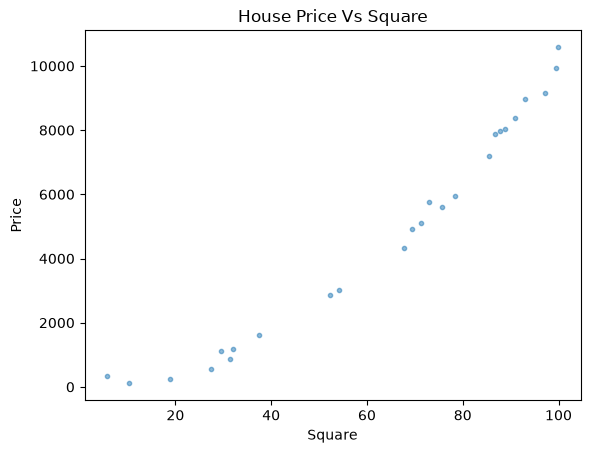

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(162)
# Create data
N = 25
x = np.random.rand(N)*100
y = x**2 + np.random.normal(1,2,size=N)*100
colors = (0,0,0)
area = np.pi*3

# Plot
plt.scatter(x, y, s=area, alpha=0.5)
plt.title('House Price Vs Square')
plt.xlabel('Square')
plt.ylabel('Price')
plt.show()

$x=60$ ?

### More Features
Now what if we know the age of the house ?

$(age,square)\rightarrow price$

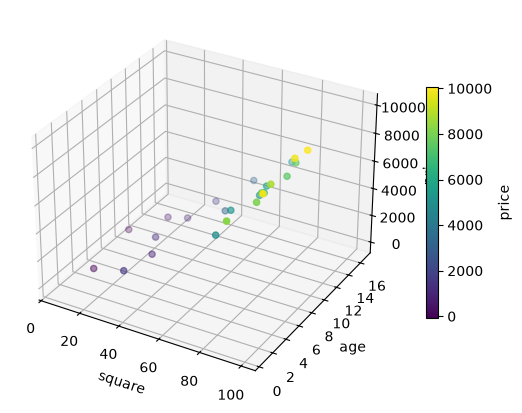

In [2]:
# Create data
np.random.seed(162)
N = 25
x = np.random.rand(N)*100
age = np.random.rand(N)*18
y = x**2 + 0.5*age + np.random.normal(1,2,size=N)*100

# 3-D scatter plot with matplotlib
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(projection='3d')
points = ax.scatter(x, age, y, c=y)
ax.set_xlabel('square')
ax.set_ylabel('age')
ax.set_zlabel('price')
fig.colorbar(points, label='price', shrink=0.6)
plt.show()

### High Dimensional Features
$x\in R^d$

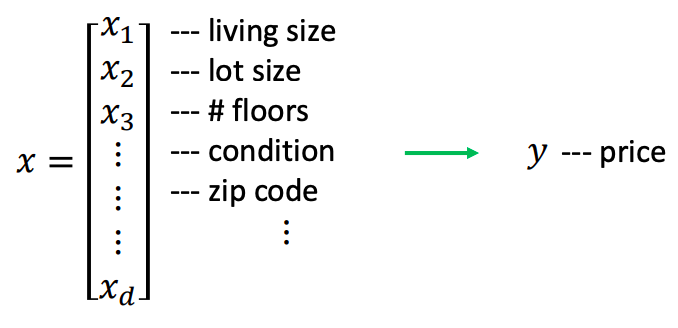

## Four kinds of machine learning tasks

Machine learning tasks split into two families, depending on whether the data comes with the answer we want to predict:

| Family | Task | The model outputs | Everyday example | Today's example | scikit-learn |
|---|---|---|---|---|---|
| **Supervised**: each sample has an answer `y` | Regression | a number | the price of a house | diabetes: BMI → disease progression | `LinearRegression` |
| | Classification | a category | spam or not spam | iris: measurements → species | `KNeighborsClassifier` |
| **Unsupervised**: only the samples `X` | Clustering | a group for each sample | customer segments | iris without the species | `KMeans` |
| | Dimensionality reduction | fewer features per sample | 30 features → a 2-D picture | breast cancer: 30 features → 2 | `PCA` |

![The four kinds of machine learning tasks](img/ml_tasks.png)

### Quick quiz: which task is it?

For each problem, decide: regression, classification, clustering or dimensionality reduction? Then click **Answer**.

**1.** Predict tomorrow's maximum temperature in Tel Aviv from the weather of the last 30 days.

<details><summary>Answer</summary>

**Regression**: the answer is a number.

</details>

**2.** Decide whether a new email is spam, using thousands of emails that users already marked as spam or not spam.

<details><summary>Answer</summary>

**Classification**: two categories, and we have labelled examples.

</details>

**3.** An online shop wants to split its customers into groups with similar shopping habits. Nobody has defined the groups in advance.

<details><summary>Answer</summary>

**Clustering**: there are no labels; the algorithm finds the groups.

</details>

**4.** Recognise the handwritten digit, 0 to 9, in a scanned image.

<details><summary>Answer</summary>

**Classification**: ten categories.

</details>

**5.** Each of 1,000 songs is described by 50 audio features. Draw the songs as dots on a 2-D plot, so that similar songs end up close to each other.

<details><summary>Answer</summary>

**Dimensionality reduction**: 50 features → 2.

</details>

**6.** Estimate how many minutes a taxi ride will take, from the pickup point, the destination and the time of day.

<details><summary>Answer</summary>

**Regression**: the answer is a number of minutes.

</details>

**Bonus.** Predict the star rating, 1 to 5, that a user will give to a movie. Is it regression or classification?

<details><summary>Answer</summary>

**Both are possible.** As classification, the five ratings are five unrelated categories. As regression, the rating is a number, so predicting 4 when the truth is 5 is a smaller mistake than predicting 1. The choice depends on what kind of mistake matters.

</details>

## The scikit-learn workflow

Every model in scikit-learn is used in the same few steps, whatever the task:

```python
model = SomeModel(hyperparameters)   # 1. choose a model and its settings
model.fit(X_train, y_train)          # 2. learn from the training data
y_pred = model.predict(X_new)        # 3. predict for new samples
model.score(X_test, y_test)          # 4. measure how good the predictions are
```

* `X` is a 2-D array with one row per sample and one column per feature, shape `(n_samples, n_features)`; `y` holds one answer per sample, shape `(n_samples,)`.
* Unsupervised models have no answers, so they are fit with `model.fit(X)` alone.

Not sure which model to pick? scikit-learn's [Choosing the right estimator](https://scikit-learn.org/stable/machine_learning_map.html) map is a good start.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets


def title(text, *values):
    # print the explanation in bold, then the values unchanged:
    # "\033[1m" turns bold on, "\033[0m" turns it off
    print("\033[1m" + text + "\033[0m", *values)

## Regression

**Question:** can we predict how much a patient's diabetes gets worse within a year from their body mass index (BMI)?

We follow the scikit-learn workflow, one step at a time: load → look → prepare `X` and `y` → fit → predict → evaluate.

### Load the data

`as_frame=True` returns the data as a pandas DataFrame: 442 patients, 10 measurements each, and the column `target`, which measures how much the disease progressed after one year. The measurements are already scaled, which is why they are small numbers around 0.

In [4]:
diabetes = datasets.load_diabetes(as_frame=True)
# The six blood tests are called s1 ... s6 in the dataset; give them readable names
df_diabetes = diabetes.frame.rename(columns={
    's1': 'total_cholesterol',
    's2': 'ldl_bad_cholesterol',
    's3': 'hdl_good_cholesterol',
    's4': 'cholesterol_hdl_ratio',
    's5': 'log_triglycerides',
    's6': 'blood_sugar',
})
title("shape of df_diabetes:", df_diabetes.shape)
df_diabetes.head(3)

shape of df_diabetes: (442, 11)


,age,sex,bmi,bp,total_cholesterol,ldl_bad_cholesterol,hdl_good_cholesterol,cholesterol_hdl_ratio,log_triglycerides,blood_sugar,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0


### Look at the data

Before fitting a model, plot the data. Does the target go up or down as BMI grows?

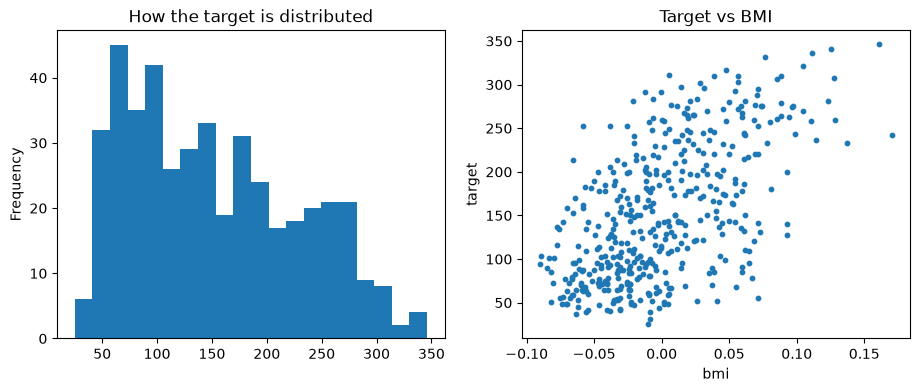

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_diabetes['target'].plot(kind='hist', bins=20, ax=axes[0], title='How the target is distributed')
df_diabetes.plot('bmi', 'target', kind='scatter', s=10, ax=axes[1], title='Target vs BMI')
plt.show()

### Your turn: prepare `X` and `y`

scikit-learn expects

* `X`: a 2-D array, one row per patient and one column per feature, here shape `(442, 1)`;
* `y`: a 1-D array, one target per patient, shape `(442,)`.

Build `X` from the column `bmi` and `y` from the column `target`.

Hint: `df_diabetes[['bmi']]`, with two pairs of brackets, is a DataFrame with one column, so it is 2-D; `df_diabetes['bmi']` is a Series, so it is 1-D. `.to_numpy()` turns either one into a NumPy array.

In [6]:
X = None   # the bmi column, shape (442, 1)
y = None   # the target column, shape (442,)

### Check your work

In [7]:
if X is None or y is None:
    print("Not done yet: write your code in the cell above and run it.")
else:
    assert X.shape == (442, 1), f"X should have shape (442, 1), got {X.shape}"
    assert y.shape == (442,), f"y should have shape (442,), got {y.shape}"
    title("Correct! shape of X:", X.shape)
    title("shape of y:", y.shape)

Not done yet: write your code in the cell above and run it.


In [8]:
# Solution
X = df_diabetes[['bmi']].to_numpy()
y = df_diabetes['target'].to_numpy()

### Fit the model

`fit` finds the straight line $\hat{y} = a \cdot \text{bmi} + b$ that is closest to the points. After fitting, the slope $a$ is stored in `model.coef_` and the intercept $b$ in `model.intercept_`.

In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)
title("slope a, how much the target grows per unit of bmi:", model.coef_[0].round(1))
title("intercept b, the prediction when bmi is 0:", round(model.intercept_, 1))

slope a, how much the target grows per unit of bmi: 949.4
intercept b, the prediction when bmi is 0: 152.1


### Your turn: predict for new patients

Two new patients have BMI values `0.05` and `-0.02`, on the same scale as the data. **First predict:** which of them gets the higher prediction? Then use `model.predict` to compute both predictions and store them in `pred`.

Hint: `predict` expects the same shape as `X`: a 2-D array with one row per patient, such as `[[0.05], [-0.02]]`.

In [10]:
pred = None   # replace None with your code

### Check your work

In [11]:
if pred is None:
    print("Not done yet: write your code in the cell above and run it.")
else:
    assert len(pred) == 2, f"expected 2 predictions, got {len(pred)}"
    assert abs(pred[0] - 199.6) < 0.1 and abs(pred[1] - 133.1) < 0.1, f"wrong predictions: {pred}"
    title("Correct! predictions for bmi 0.05 and -0.02:", np.round(pred, 1))

Not done yet: write your code in the cell above and run it.


In [12]:
# Solution
pred = model.predict([[0.05], [-0.02]])

### Evaluate

`model.score(X, y)` returns $R^2$: 1 means perfect predictions, 0 means no better than always predicting the average target. Here we measure on the same patients the model was trained on; the next section keeps a separate test set.

R^2 on the training data: 0.34


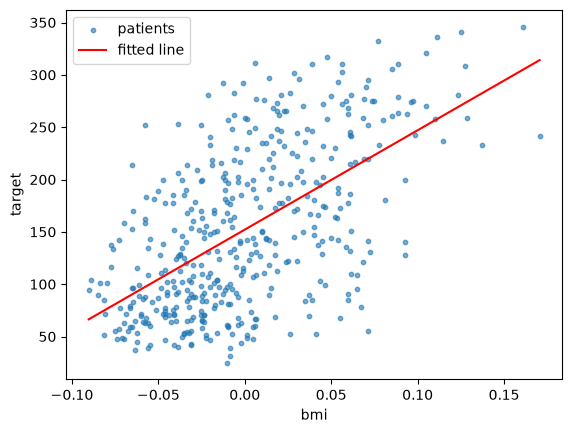

In [13]:
title("R^2 on the training data:", round(model.score(X, y), 2))

bmi = np.linspace(X.min(), X.max(), 50).reshape(-1, 1)
plt.scatter(X, y, s=10, alpha=0.6, label='patients')
plt.plot(bmi, model.predict(bmi), color='red', label='fitted line')
plt.xlabel('bmi')
plt.ylabel('target')
plt.legend()
plt.show()

**Think:** $R^2$ is only about 0.34, so BMI alone explains about a third of the differences between patients. How could we do better?

<details><summary>Answer</summary>

Use more features. With all 10 measurements, `LinearRegression` reaches $R^2 \approx 0.52$ on the training data.

</details>

### Open question: does cholesterol protect against diabetes?

Following the answer above, we fit a model on all 10 measurements and look at its coefficients. A coefficient says how much the prediction changes when that measurement goes up while all the others stay the same.

R^2 with all 10 measurements: 0.52


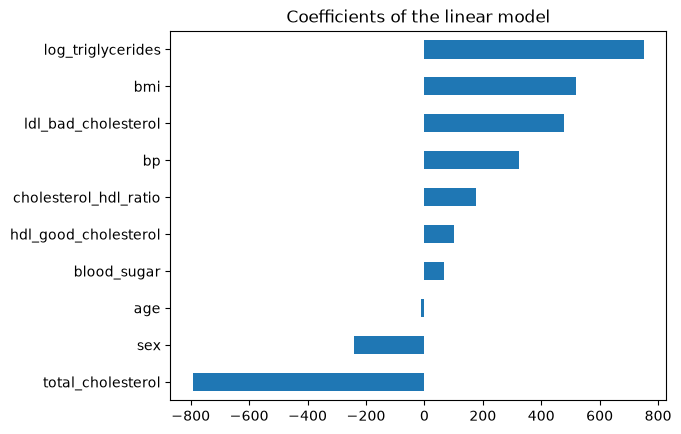

In [14]:
X_all = df_diabetes.drop(columns='target')
model_all = LinearRegression().fit(X_all, y)
title("R^2 with all 10 measurements:", round(model_all.score(X_all, y), 2))

coefs = pd.Series(model_all.coef_, index=X_all.columns)
coefs.sort_values().plot(kind='barh', title='Coefficients of the linear model')
plt.show()

`total_cholesterol` gets a large **negative** coefficient, about −790: taken literally, the higher a patient's cholesterol, the **less** their diabetes progresses. At the same time `ldl_bad_cholesterol`, the "bad" cholesterol, gets a large positive one, about +480.

**Should a doctor tell patients to raise their cholesterol?** Discuss with your neighbour. Run the three clues below before opening the discussion points; there is no single right answer.

In [15]:
# Clue 1: on its own, how is total cholesterol related to the target? And to LDL?
title("correlation of total_cholesterol with the target:",
      round(df_diabetes['total_cholesterol'].corr(df_diabetes['target']), 2))
title("correlation of total_cholesterol with ldl_bad_cholesterol:",
      round(df_diabetes['total_cholesterol'].corr(df_diabetes['ldl_bad_cholesterol']), 2))

correlation of total_cholesterol with the target: 0.21
correlation of total_cholesterol with ldl_bad_cholesterol: 0.9


In [16]:
# Clue 2: drop total_cholesterol and fit again
X_less = X_all.drop(columns='total_cholesterol')
model_less = LinearRegression().fit(X_less, y)
title("R^2 without total_cholesterol:", round(model_less.score(X_less, y), 3))
title("coefficient of ldl_bad_cholesterol now:",
      round(pd.Series(model_less.coef_, index=X_less.columns)['ldl_bad_cholesterol']))

R^2 without total_cholesterol: 0.514
coefficient of ldl_bad_cholesterol now: -143


Clue 3 uses `Ridge`: linear regression with a penalty on large coefficients. Among models that fit about equally well, it prefers the one with the smallest coefficients.

In [17]:
# Clue 3: the same model with Ridge
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=0.1).fit(X_all, y)
title("R^2 of Ridge:", round(ridge.score(X_all, y), 3))
pd.DataFrame({'LinearRegression': model_all.coef_, 'Ridge': ridge.coef_}, index=X_all.columns).round(0)

R^2 of Ridge: 0.513


,LinearRegression,Ridge
age,-10.0,1.0
sex,-240.0,-207.0
bmi,520.0,490.0
bp,324.0,302.0
total_cholesterol,-792.0,-83.0
ldl_bad_cholesterol,477.0,-71.0
hdl_good_cholesterol,101.0,-189.0
cholesterol_hdl_ratio,177.0,116.0
log_triglycerides,751.0,444.0
blood_sugar,68.0,87.0


<details><summary>Some points for the discussion</summary>

* On its own, higher total cholesterol goes with a **worse** disease (correlation +0.21). The negative sign appears only inside the model that uses all the measurements.
* `total_cholesterol` and `ldl_bad_cholesterol` are strongly correlated (0.90): they carry almost the same information. The model can raise one coefficient and lower the other without changing its predictions much, so the individual coefficients are unstable. This is called **multicollinearity**.
* The evidence: without `total_cholesterol`, $R^2$ hardly changes (0.518 → 0.514), but the coefficient of LDL flips from about +480 to about −140.
* `Ridge` keeps almost the same $R^2$ (0.513), and the two huge opposite coefficients shrink to small values.
* A model that predicts well does not explain **why**. These data are observations of patients, not an experiment: even a stable coefficient shows a correlation, not that changing a patient's cholesterol would change their disease.

</details>

## Classification

**Question:** a botanist measures an iris flower. Can we tell which of three species it is? The answer is a category, not a number, so this is classification.

The steps: load → look → split → fit and predict → evaluate.

### Load the data

150 flowers, 50 of each species: *setosa*, *versicolor* and *virginica*. Each flower has 4 measurements in cm: the length and width of its sepal and of its petal.

In [18]:
iris = datasets.load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris['species'] = iris.target_names[iris.target]
title("shape of df_iris:", df_iris.shape)
df_iris.sample(5, random_state=0)

shape of df_iris: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
114,5.8,2.8,5.1,2.4,virginica
62,6.0,2.2,4.0,1.0,versicolor
33,5.5,4.2,1.4,0.2,setosa
107,7.3,2.9,6.3,1.8,virginica
7,5.0,3.4,1.5,0.2,setosa


### Look at the data

Which pair of measurements separates the three species better: the sepal or the petal?

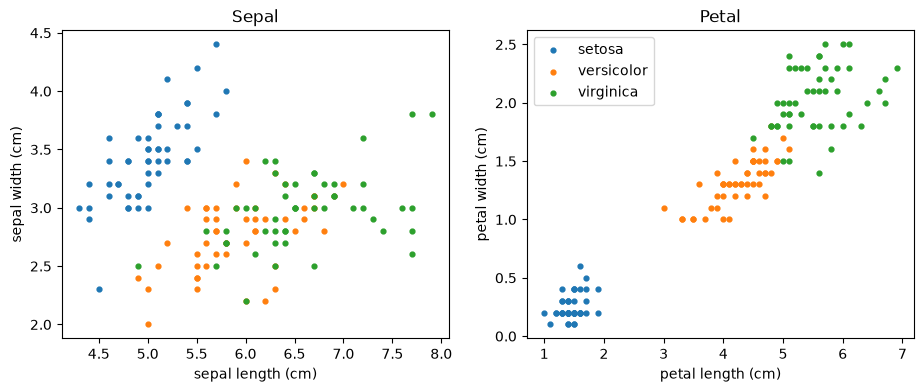

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in iris.target_names:
    rows = df_iris[df_iris['species'] == name]
    axes[0].scatter(rows['sepal length (cm)'], rows['sepal width (cm)'], s=12, label=name)
    axes[1].scatter(rows['petal length (cm)'], rows['petal width (cm)'], s=12, label=name)
axes[0].set(title='Sepal', xlabel='sepal length (cm)', ylabel='sepal width (cm)')
axes[1].set(title='Petal', xlabel='petal length (cm)', ylabel='petal width (cm)')
axes[1].legend()
plt.show()

### Prepare `X` and `y`, then split

In the petal plot the species barely overlap, so we use the two petal measurements as features.

To judge a model fairly we must test it on flowers it has **never seen**. `train_test_split` keeps 20% of the flowers aside as a test set; the model learns only from the other 80%.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X = iris.data[:, 2:]                   # petal length and petal width
y = iris.target_names[iris.target]     # the species name of each flower
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
title("training set, X and y:", X_train.shape, y_train.shape)
title("test set, X and y:", X_test.shape, y_test.shape)

training set, X and y: (120, 2) (120,)
test set, X and y: (30, 2) (30,)


### Your turn: train a k-nearest-neighbours classifier

To classify a new flower, k-nearest neighbours (KNN) finds the `k` training flowers closest to it and takes a majority vote of their species.

Create `KNeighborsClassifier(n_neighbors=5)` and fit it on the **training set only**.

In [21]:
model = None   # create the classifier and fit it on the training set

### Check your work

In [22]:
if model is None:
    print("Not done yet: write your code in the cell above and run it.")
else:
    assert getattr(model, 'n_samples_fit_', None) == 120, "fit the model on the training set, 120 flowers"
    title("Correct! number of flowers the model was fit on:", model.n_samples_fit_)

Not done yet: write your code in the cell above and run it.


In [23]:
# Solution
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U10](3,)","['setosa','versicolor','virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [24]:
# predict the species of the 30 test flowers, as in the Regression section
y_pred = model.predict(X_test)
title("predicted species of the first 5 test flowers:", y_pred[:5])
title("true species of the first 5 test flowers:", y_test[:5])

predicted species of the first 5 test flowers: ['virginica' 'versicolor' 'setosa' 'virginica' 'setosa']
true species of the first 5 test flowers: ['virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


### Your turn: accuracy

Accuracy is the fraction of test flowers whose species was predicted correctly. Compute it yourself from `y_pred` and `y_test` and store it in `accuracy`.

Hint: `y_pred == y_test` is an array of `True`/`False`, and the mean of such an array is the fraction of `True`.

In [25]:
accuracy = None   # replace None with your code

### Check your work

In [26]:
if accuracy is None:
    print("Not done yet: write your code in the cell above and run it.")
else:
    assert abs(accuracy - 1.0) < 1e-9, f"expected 1.0, got {accuracy}"
    title("Correct! accuracy:", float(accuracy))
    title("model.score(X_test, y_test) computes the same number:", model.score(X_test, y_test))

Not done yet: write your code in the cell above and run it.


In [27]:
# Solution
accuracy = np.mean(y_pred == y_test)

### Precision and recall

Accuracy is one number for all species together. `classification_report` gives two numbers for each species:

* **precision**: of the flowers predicted as this species, the fraction that really are;
* **recall**: of the flowers of this species, the fraction that the model found.

The order of the arguments matters: `classification_report(y_true, y_pred)`.

In [28]:
from sklearn import metrics
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        11
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00         6

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



![Precision and recall](img/Precisionrecall.svg)

*Image: Walber, [Precisionrecall.svg](https://commons.wikimedia.org/wiki/File:Precisionrecall.svg), CC BY-SA 4.0, via Wikimedia Commons.*

### Try it: how many neighbours?

`k` is a **hyper-parameter**: we choose it, the model does not learn it. **Before running the cell, predict:** what happens to the test accuracy when `k` is very large, such as 100? Remember that the training set has only 120 flowers, about 40 of each species.

In [29]:
for k in [1, 5, 15, 50, 100]:
    acc = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_test, y_test)
    title(f"k = {k:3}, test accuracy:", round(acc, 3))

k =   1, test accuracy: 1.0
k =   5, test accuracy: 1.0
k =  15, test accuracy: 1.0
k =  50, test accuracy: 0.967
k = 100, test accuracy: 0.567


<details><summary>Why does the accuracy drop?</summary>

With `k = 100`, most of the training set votes, so flowers of other species, far away from the new flower, outvote its true neighbours. A good `k` is large enough to ignore a single odd neighbour, but small enough to stay local.

</details>

### Cross-validation

The test set has only 30 flowers, so its accuracy depends on which flowers happened to land in it. Cross-validation splits the data 5 times, each time testing on a different fifth, and reports all 5 scores.

In [30]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(KNeighborsClassifier(n_neighbors=5), X, y, cv=5)
title("accuracy of each of the 5 splits:", scores.round(3))
title("mean accuracy:", round(scores.mean(), 3))
title("standard deviation:", round(scores.std(), 3))

accuracy of each of the 5 splits: [0.967 0.967 0.933 0.967 1.   ]
mean accuracy: 0.967
standard deviation: 0.021


## Clustering

**Question:** suppose we measured the 150 flowers, but nobody told us their species. Can an algorithm discover groups in the data by itself? There are no labels to learn from, so this is **unsupervised** learning.

The steps: fit on the measurements only → look at the clusters → compare with the true species → choose the number of clusters.

### Your turn: fit k-means

k-means splits the samples into `k` clusters: it places `k` centres, assigns every sample to its nearest centre, moves each centre to the mean of its samples, and repeats until the clusters stop changing.

Create `KMeans(n_clusters=3, random_state=0)` and fit it on `X`, the 4 measurements of each flower. The species `y` stay aside; we use them only at the end, to check the result.

Hint: an unsupervised model is fit with `fit(X)` alone, there is no `y`.

In [31]:
from sklearn.cluster import KMeans

X = iris.data   # the 4 measurements of each flower, without the species
model = None    # create KMeans with 3 clusters and random_state=0, and fit it on X

### Check your work

In [32]:
if model is None:
    print("Not done yet: write your code in the cell above and run it.")
else:
    assert getattr(model, 'n_clusters', None) == 3, "use n_clusters=3"
    assert len(getattr(model, 'labels_', [])) == 150, "fit the model on X, all 150 flowers"
    title("Correct! number of flowers in each cluster:", np.bincount(model.labels_))

Not done yet: write your code in the cell above and run it.


In [33]:
# Solution
model = KMeans(n_clusters=3, random_state=0)
model.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 4)","[[

### Look at the clusters

After fitting, `model.labels_` holds the cluster of each flower: 0, 1 or 2. The left plot colours the flowers by cluster, the right one by their true species, which k-means never saw.

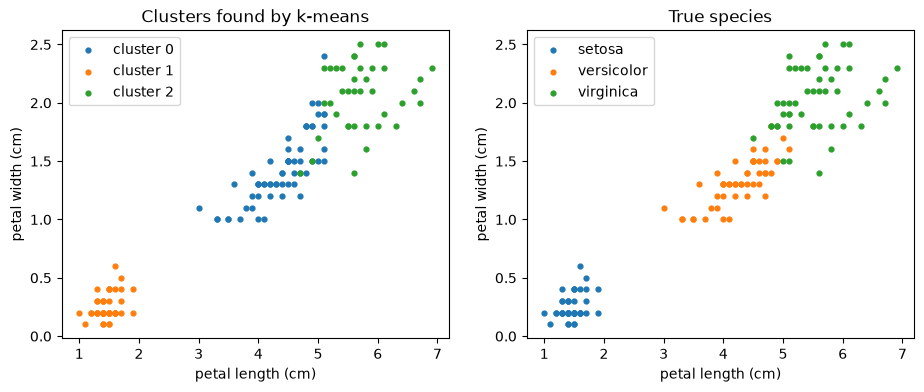

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for c in range(3):
    axes[0].scatter(X[model.labels_ == c, 2], X[model.labels_ == c, 3], s=12, label=f'cluster {c}')
for name in iris.target_names:
    axes[1].scatter(X[y == name, 2], X[y == name, 3], s=12, label=name)
axes[0].set(title='Clusters found by k-means', xlabel='petal length (cm)', ylabel='petal width (cm)')
axes[1].set(title='True species', xlabel='petal length (cm)', ylabel='petal width (cm)')
axes[0].legend()
axes[1].legend()
plt.show()

### Try it: do the cluster numbers match the species?

In `iris.target`, setosa is 0, versicolor 1 and virginica 2. **Before running the cell, predict:** is cluster 0 the setosa flowers? `pd.crosstab` counts how many flowers of each species fall into each cluster.

In [35]:
pd.crosstab(model.labels_, y, rownames=['cluster'], colnames=['species'])

species,setosa,versicolor,virginica
cluster,,,
0,0,47,14
1,50,0,0
2,0,3,36


<details><summary>What does the table show?</summary>

The cluster numbers are only names chosen by k-means; they do not have to match the species numbers. Here cluster 1 is exactly the 50 setosa flowers. Clusters 0 and 2 are mostly versicolor and mostly virginica, but 17 flowers land in the "wrong" cluster: in the petal plot, these two species overlap.

</details>

## Dimensionality reduction (PCA)

Dimensionality reduction is another unsupervised learning problem (that is, it does not require labels). It aims to project datapoints into a lower dimensional space while preserving distances between datapoints.

Lets take a look at the breast cancer dataset with dimensionality reduction

In [37]:
bc = datasets.load_breast_cancer()

In [38]:
print(bc.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [39]:
X = bc.data
y = bc.target_names[bc.target]

In [40]:
bc.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

For the **picture** below we scale and project all samples: this is unsupervised visualisation, no model is evaluated.

In [41]:
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(X) # normalizing the features

In [42]:
np.mean(X,axis=0),np.std(X,axis=0)

(array([-3.16286735e-15, -6.53060890e-15, -7.07889127e-16, -8.79983452e-16,
         6.13217737e-15, -1.12036918e-15, -4.42138027e-16,  9.73249991e-16,
        -1.97167024e-15, -1.45363120e-15, -9.07641468e-16, -8.85349205e-16,
         1.77367396e-15, -8.29155139e-16, -7.54180940e-16, -3.92187747e-16,
         7.91789988e-16, -2.73946068e-16, -3.10823423e-16, -3.36676596e-16,
        -2.33322442e-15,  1.76367415e-15, -1.19802625e-15,  5.04966114e-16,
        -5.21317026e-15, -2.17478837e-15,  6.85645643e-16, -1.41265636e-16,
        -2.28956670e-15,  2.57517109e-15]),
 array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]))

In [43]:
from sklearn.decomposition import PCA
pca_breast = PCA(n_components=2)
X_PCA = pca_breast.fit_transform(X)

In [44]:
pd.DataFrame(data = X_PCA, columns = ['pc_1', 'pc_2'])

,pc_1,pc_2
0,9.192837,1.948583
1,2.387802,-3.768172
2,5.733896,-1.075174
3,7.122953,10.275589
4,3.935302,-1.948072
...,...,...
564,6.439315,-3.576817
565,3.793382,-3.584048
566,1.256179,-1.902297
567,10.374794,1.672010


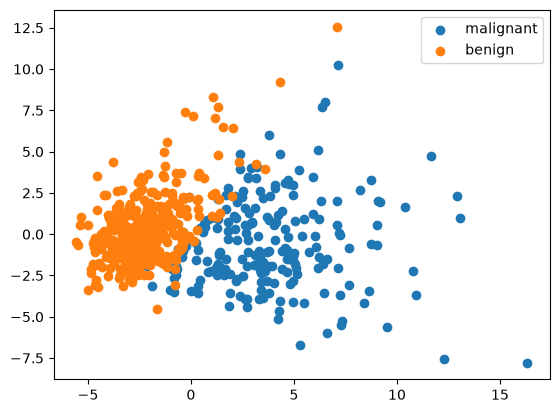

In [45]:
for name in bc.target_names:
    plt.scatter(X_PCA[y == name, 0], X_PCA[y == name, 1], label=name)
plt.legend()

### Training a classifier without data leakage

The scaler and PCA above were fit on **all** samples, which is fine for a picture. For a model we evaluate, every step must be fit on the **training set only**; otherwise information from the test set leaks into training and the score is too optimistic.
A `Pipeline` chains the steps and guarantees that `fit` only ever sees the training data. So we split the raw, unscaled features first:

accuracy: 0.8936170212765957


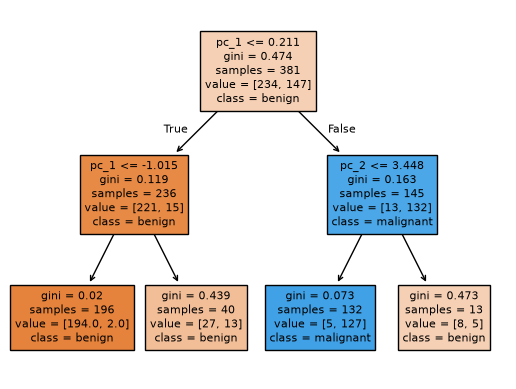

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn import tree

X_raw = bc.data   # original, unscaled features
x_train, x_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.33, random_state=1)

clf = make_pipeline(StandardScaler(), PCA(n_components=2), tree.DecisionTreeClassifier(max_depth=2))
clf.fit(x_train, y_train)   # scaler, PCA and tree are fit on the training set only
print('accuracy:', clf.score(x_test, y_test))
tree.plot_tree(clf[-1], feature_names=['pc_1', 'pc_2'], class_names=list(clf.classes_), filled=True);

How balanced are the classes in the training set? A classifier that always predicts the majority class would already reach the larger fraction, so the tree's accuracy should be compared with it.

In [47]:
pd.Series(y_train).value_counts(normalize=True)

benign       0.614173
malignant    0.385827
Name: proportion, dtype: float64